c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "dtf2d" yielded 1 of "dubious year (Note 6)"

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "utctai" yielded 1 of "dubious year (Note 3)"

c:\src\ASEN5053\project\python\.conda\lib\site-packages\erfa\core.py:154: ErfaWarning:

ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"



([<matplotlib.lines.Line2D at 0x1c215e84220>],
 <matplotlib.lines.Line2D at 0x1c215e84e80>)

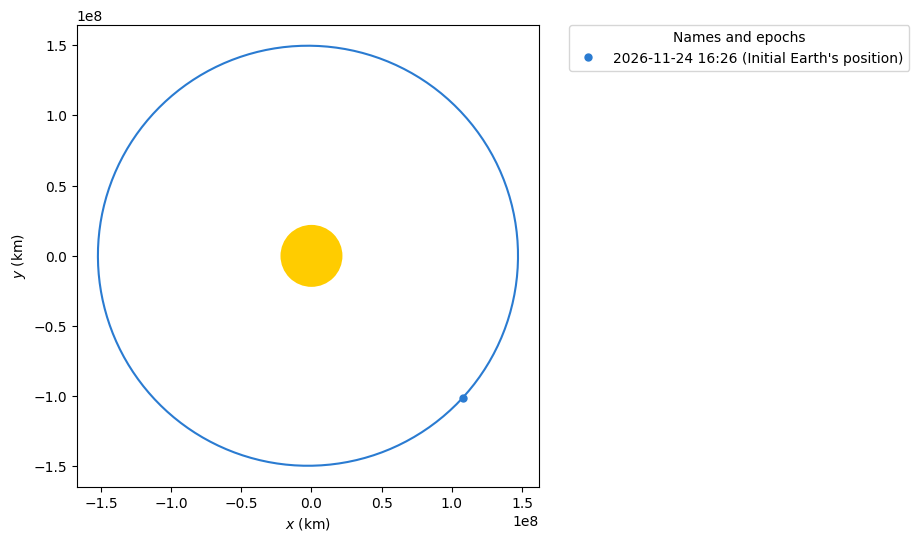

In [28]:
from astropy import units as u
from astropy.time import Time
from astropy.coordinates import solar_system_ephemeris

solar_system_ephemeris.set("jpl")

import numpy as np

from poliastro.bodies import Sun, Earth, Jupiter
from poliastro.ephem import Ephem
from poliastro.frames import Planes
from poliastro.maneuver import Maneuver
from poliastro.plotting import StaticOrbitPlotter
from poliastro.twobody import Orbit
from poliastro.util import norm, time_range
from matplotlib import colors
from matplotlib import markers
from datetime import datetime

# All the data for Juno's mission is sorted [here](https://github.com/poliastro/poliastro/wiki/EuroPython:-Per-Python-ad-Astra). The main maneuvers that the spacecraft will perform are listed down:

#* Inner cruise phase 1: This will set Juno in a new orbit around the sun.
#1* Inner cruise phase 2: Fly-by around Earth. Gravity assist is performed.
#* Inner cruise phase 3: Jupiter insertion maneuver.

#Let us first define the main dates and other relevant parameters of the mission:

## Main dates
date_launch = Time("2026-11-24 16:25", scale="utc").tdb
date_flyby = Time("2029-01-16 19:21", scale="utc").tdb
date_arrival = Time("2031-08-02 03:18", scale="utc").tdb

# Atlas V supplied a launch energy
C_3 = 26.9 * u.km**2 / u.s**2

#With previous dates we can create the different orbits that define the position of the Earth along the mission:

# Plot initial Earth's position
Earth.plot(date_launch, label="Initial Earth's position")




C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_45716\2521324231.py:31: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



([<matplotlib.lines.Line2D at 0x1c221379280>], None)

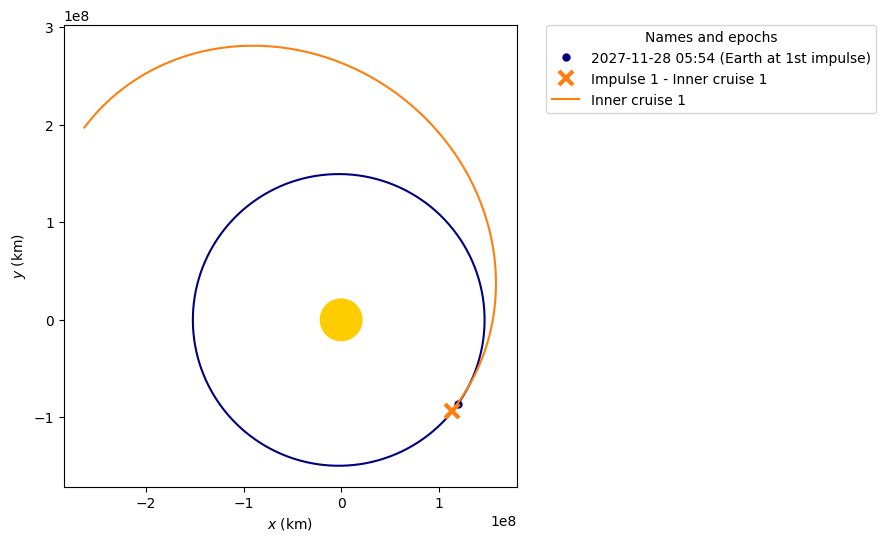

In [64]:
#Since both Earth states have been obtained (initial and flyby) we can now solve for Juno's maneuvers. The first one sets Juno into an elliptical orbit around the Sun so that it applies a gravity assist around the Earth:

earth = Ephem.from_body(
    Earth, time_range(date_launch, end=date_arrival, periods=500)
)

r_e0, v_e0 = earth.rv(date_launch)

# Assume that the insertion velocity is tangential to that of the Earth
dv = C_3**0.5 * v_e0 / norm(v_e0)

# We create the maneuver from impulse constructor
man = Maneuver.impulse(dv)

#If we now apply the previous maneuver to the Junos's initial orbit (assume it is the Earth's one for simplicity), we will obtain the orbit around the Sun for Juno. The first inner cruise maneuver is defined just till the ahelion orbit. While Juno is traveling around its new orbit, Earth is also moving. After Juno reaches the aphelion it will be necessary to apply a second maneuver so the flyby is performed around Earth. Once that is achieved a final maneuver will be made in order to benefit from the gravity assist. Let us first propagate Juno's orbit till the aphelion:

ss_e0 = Orbit.from_ephem(Sun, earth, date_launch)
ss_efly = Orbit.from_ephem(Sun, earth, date_flyby)

# Inner Cruise 1
ic1 = ss_e0.apply_maneuver(man)
ic1_end = ic1.propagate_to_anomaly(180.0 * u.deg)

legend_l = date_launch.strftime('%Y-%m-%d') + " (Earth at launch)"
legend_i1 = "Inner cruise 1"
# We can check new bodies positions
plotter = StaticOrbitPlotter()
plotter.plot_body_orbit(Earth, ic1_end.epoch, label="Earth at 1st impulse", color="navy")
plotter.plot_maneuver(ss_e0, man, color="C1", label=legend_i1)
plotter.plot_trajectory(
    ic1.sample(max_anomaly=180 * u.deg),
    label="Inner cruise 1",
    color="C1",
)


Initial impulse: (<Quantity 0. s>, <Quantity [-985.11424846, -816.19284987, -353.41493518] m / s>)
Final impulse: (<Quantity 35904452.54834227 s>, <Quantity [ 7054.57876711, -4892.17209431, -2118.56252512] m / s>)


C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_45716\868843378.py:37: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



[('Impulse 1 - Inner cruise 2',
  ([<matplotlib.lines.Line2D at 0x1c2220a0970>],)),
 ('Inner cruise 2', ([<matplotlib.lines.Line2D at 0x1c2220b0c40>], None)),
 ('Impulse 2 - Inner cruise 2',
  ([<matplotlib.lines.Line2D at 0x1c2220bd1f0>],))]

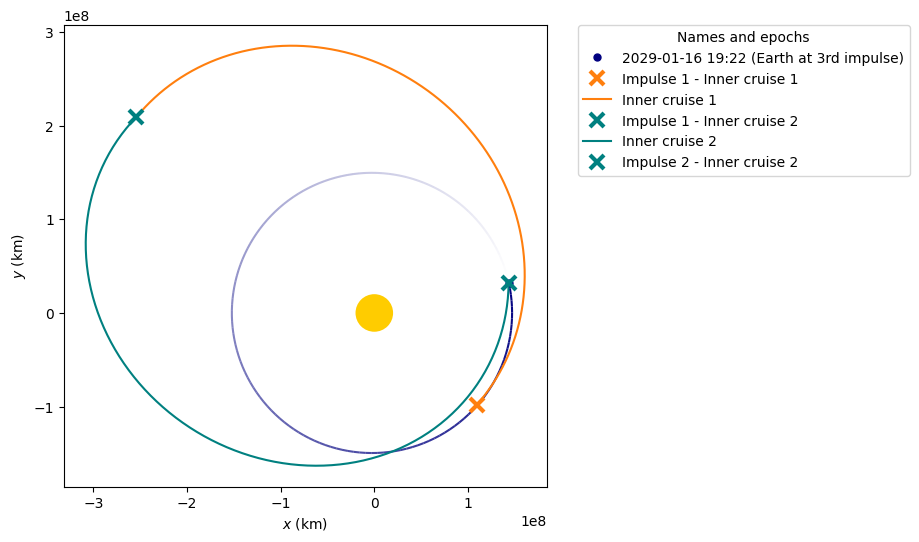

In [65]:
# We can check that the period of the orbit is similar to the one stated in the mission's documentation. Remember that in the previous plot we only plotter half of the orbit for Juno's first maneuver and the period is the time that would take Juno to complete one full revolution around this new orbit.
ic1.period.to(u.day)

#Notice that in the previous plot that Earth's position is not the initial one since while Juno is moving Earth also does. We now solve for the Lambert maneuver in order to perform a flyby around the earth when it is at flyby date:

# Let's compute the Lambert solution to do the flyby of the Earth
man_flyby = Maneuver.lambert(ic1_end, ss_efly)
imp_a, imp_b = man_flyby.impulses

print("Initial impulse:", imp_a)
print("Final impulse:", imp_b)

# Check the initial delta-V
dv_a = imp_a[-1]
norm(dv_a.to(u.km / u.s))

#We can now solve for the flyby orbit that will help Juno with the gravity assist. Again, the inner phase 2 maneuver is defined till Juno reaches Earth's position for the flyby date although the full orbit is plotted:

# Let us apply the maneuver
ic2, ss_flyby = ic1_end.apply_maneuver(man_flyby, intermediate=True)

# We propagate the transfer orbit till the flyby occurs
ic2_end = ic2.propagate(date_flyby)

legend_i2 = "2029-01-16 (3rd impulse)"

plotter = StaticOrbitPlotter()
plotter.plot_body_orbit(
    Earth,
    ss_efly.epoch,
    label="Earth at 3rd impulse",
    trail=True,
    color="navy"
)
plotter.plot_maneuver(ss_e0, man, color="C1", label=legend_i1)
plotter.plot_trajectory(
    ic1.sample(max_anomaly=180 * u.deg), label="Inner cruise 1", color="C1"
)
plotter.plot_maneuver(
    ic1_end,
    man_flyby,
    label="Inner cruise 2",
    color="teal",
)




Initial impulse: (<Quantity 0. s>, <Quantity [-3364.26566902, -2364.22919278,  -583.0626105 ] m / s>)
Final impulse: (<Quantity 80121419.99884774 s>, <Quantity [5789.83332141, 1040.88566364,  204.3507107 ] m / s>)


C:\Users\aussiebuttz\AppData\Local\Temp\ipykernel_45716\4154504550.py:35: DeprecationWarning:

Specifying min_anomaly and max_anomaly in method `sample` is deprecated and will be removed in a future release, use `Orbit.to_ephem(strategy=TrueAnomalyBounds(min_nu=..., max_nu=...))` instead



([<matplotlib.collections.LineCollection at 0x1c215f93c40>],
 <matplotlib.lines.Line2D at 0x1c21db5d610>)

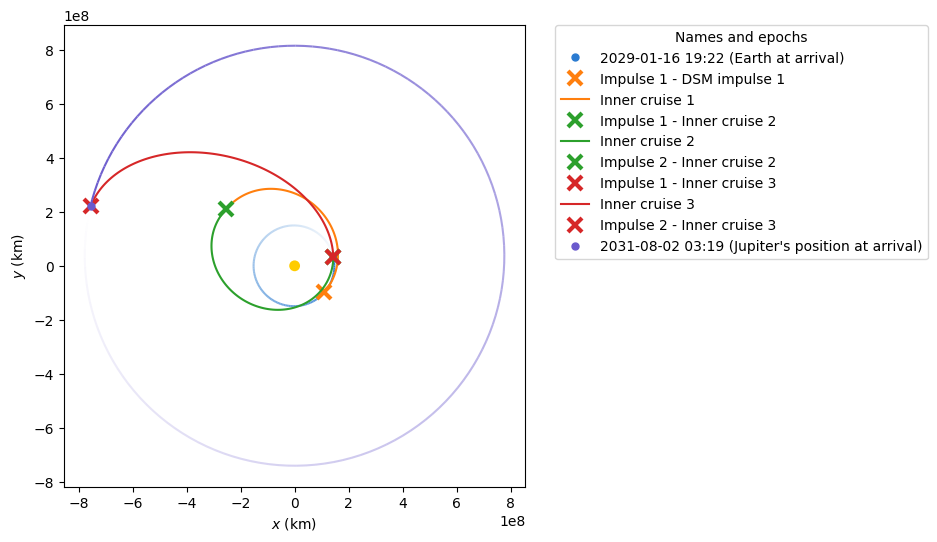

In [63]:
#We can now start solving for the maneuver that will take Juno to Jupiter. Another Lambert maneuver is required but first let us solve for Jupiter position on arrival:

# And now, go to Jupiter!
jupiter = Ephem.from_body(Jupiter, time_range(date_launch, end=date_arrival))

ss_j = Orbit.from_ephem(Sun, jupiter, date_arrival)

# Solving for maneuver to Jupiter
man_jupiter = Maneuver.lambert(ic2_end, ss_j)
imp_a, imp_b = man_jupiter.impulses

print("Initial impulse:", imp_a)
print("Final impulse:", imp_b)

#Again, we apply the maneuver:

# Apply the maneuver
ic3, ss_target = ic2_end.apply_maneuver(man_jupiter, intermediate=True)
ic3_end = ic3.propagate(date_arrival)

# Finally, we can plot all the different phases of the mission. This shows the whole power of the *poliastro* package, since a beautiful image is created showing the whole maneuvering process:

#:tags: [nbsphinx-thumbnail]

# Final plot for the whole mission
plotter = StaticOrbitPlotter()
plotter.plot_body_orbit(
    Earth,
    date_flyby,
    label="Earth at arrival",
    trail=True,
)
plotter.plot_maneuver(ss_e0, man, color="C1", label=legend_i1)
plotter.plot_trajectory(
    ic1.sample(max_anomaly=180 * u.deg), label="Inner cruise 1", color="C1"
)
plotter.plot_maneuver(
    ic1_end,
    man_flyby,
    label="Inner cruise 2",
    color="C2",
)
plotter.plot_maneuver(
    ic2_end,
    man_jupiter,
    label="Inner cruise 3",
    color="C3",
)
plotter.plot_body_orbit(
    Jupiter, date_arrival, label="Jupiter at arrival", trail=True, color="slateblue"
)
